# Inside AlexNet and ResNet: Predictions, Filters, and Shortcuts

[Open in Colab](https://colab.research.google.com/github/ZhuoranYang/sds265-fall26/blob/main/demos/13-convolutional-networks/alexnet-resnet.ipynb)

Lecture 13 follows CNNs from local filters to large image classifiers. Here
we examine two trained networks, AlexNet and ResNet-18, on a photograph. We will:

1. compute predictions using each checkpoint's image preprocessing;
2. account for the parameters and follow every intermediate tensor size;
3. inspect AlexNet's learned filters and feature maps;
4. reconstruct ResNet's identity and projection shortcuts;
5. load another ResNet-18 checkpoint from Hugging Face.

**How to run it.** In Colab, choose Runtime → Run all. The forward passes run
on CPU; a GPU runtime is used automatically when available. First run downloads
about 280 MB of TorchVision weights, one photograph, and about 45 MB for the
optional Hugging Face checkpoint.

This lesson follows the architecture progression in Ben Trevett's tutorials
and uses pretrained TorchVision models. Source credits appear at the end.

## 1. Setup and one photograph

Colab provides PyTorch and TorchVision. For a local installation, use compatible
versions from the [PyTorch installer](https://pytorch.org/get-started/locally/).
The cell chooses `cuda` when available and `cpu` otherwise. To choose CPU
explicitly, set `device = torch.device('cpu')` after this cell.

We start with the dog photograph from the PyTorch Hub example. Look at the
subject, pose, and background before running the classifiers. Later, replace
`IMAGE_PATH` with the filename of your own uploaded photograph.

PyTorch 2.10.0 device: cpu


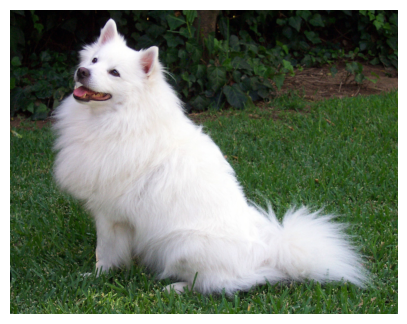

In [1]:
from pathlib import Path
import urllib.request
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torchvision import models

torch.manual_seed(26513)
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, 'device:', device)
IMAGE_PATH = Path('dog.jpg')
if not IMAGE_PATH.exists():
    urllib.request.urlretrieve('https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg', IMAGE_PATH)
image = Image.open(IMAGE_PATH).convert('RGB')
plt.figure(figsize=(5,4)); plt.imshow(image); plt.axis('off'); plt.show()

from IPython.display import Image as DisplayImage, SVG, display
FIGURE_SOURCE = 'https://d2l.ai/_images/'
def show_d2l_figure(name, width=760):
    folder = Path('figures')
    folder.mkdir(exist_ok=True)
    png = folder / f'{name}.png'
    if png.exists():
        display(DisplayImage(filename=str(png), width=width))
    else:
        # A standalone Colab notebook fetches the original public SVG directly.
        svg = folder / f'{name}.svg'
        if not svg.exists():
            urllib.request.urlretrieve(FIGURE_SOURCE + svg.name, svg)
        display(SVG(filename=str(svg)))


## 2. Predictions from pretrained models

Each checkpoint includes a preprocessing transform: resize, center crop, and
channel normalization. The transformed photograph has shape $1\times3\times224\times224$.
The network returns one logit $s_c$ for each of 1,000 ImageNet classes. Softmax
converts them to
$$p_c=\frac{e^{s_c}}{\sum_{k=1}^{1000}e^{s_k}}.$$
The top-five printout lists the largest probabilities. Their calibration on
new photographs depends on how those photographs differ from the training data.

As in Lecture 12, we switch to `eval()` and disable gradient recording for
prediction. AlexNet's dropout becomes an identity operation, and ResNet's batch
normalization uses its stored running statistics, as discussed in Lecture 13.

The table counts all parameters and then isolates the classifier. Before
running it, predict which network has more weights and where those weights sit.
For these pretrained networks, each BatchNorm layer loads its `running_mean`
and `running_var` with the ImageNet-trained checkpoint. Our photograph uses
those saved per-channel estimates. A channel mean and variance were accumulated
over training samples and spatial positions at that layer; the evaluation
photograph leaves those estimates unchanged. The small-CNN companion verifies
the moving updates and evaluation formula numerically.


In [2]:
specs = [('AlexNet', models.alexnet, models.AlexNet_Weights.DEFAULT),
         ('ResNet-18', models.resnet18, models.ResNet18_Weights.DEFAULT)]
networks, inputs, rows = {}, {}, []
for name, constructor, weights in specs:
    net = constructor(weights=weights).to(device).eval()
    x = weights.transforms()(image).unsqueeze(0).to(device)
    with torch.inference_mode():
        probability = net(x).softmax(1)[0].cpu()
    values, indices = probability.topk(5)
    print(name)
    for value, index in zip(values.tolist(), indices.tolist()):
        print(f'  {weights.meta["categories"][index]:25s} {value:.3f}')
    classifier = net.classifier if name == 'AlexNet' else net.fc
    rows.append(dict(model=name, parameters=sum(p.numel() for p in net.parameters()),
                     classifier_parameters=sum(p.numel() for p in classifier.parameters())))
    networks[name], inputs[name] = net, x
parameter_table = pd.DataFrame(rows)
parameter_table['classifier_fraction'] = parameter_table.classifier_parameters / parameter_table.parameters
display(parameter_table)
assert parameter_table.loc[0, 'parameters'] > parameter_table.loc[1, 'parameters']

AlexNet
  Samoyed                   0.724
  wallaby                   0.139
  Pomeranian                0.059
  Angora                    0.023
  Arctic fox                0.012
ResNet-18
  Samoyed                   0.885
  Arctic fox                0.046
  white wolf                0.044
  Pomeranian                0.006
  Great Pyrenees            0.005


,model,parameters,classifier_parameters,classifier_fraction
0,AlexNet,61100840,58631144,0.959580
1,ResNet-18,11689512,513000,0.043885


AlexNet has 61,100,840 parameters, compared with 11,689,512 for ResNet-18.
Most of AlexNet's weights belong to its dense classifier. ResNet-18 averages
each final feature map over space, leaving just 512 features for its final
linear layer. This is why a deeper network can have fewer parameters.

The TorchVision AlexNet follows the later *One weird trick* variant. The
Lecture 13 ImageNet result refers to the original 2012 network; the shared
ideas are learned convolutional features, ReLU, pooling, and a dense classifier.

### Follow the tensor through AlexNet

Image tensors use $N\times C\times H\times W$. $N$ is minibatch size, $C$ is channel
count, $H$, $W$ are spatial dimensions. RGB images have $C=3$. Here $N=1$;
a batch of eight photographs would replace every $N$ below by 8. For our photograph, preprocessing resizes, center-crops to $224\times 224$,
and normalizes each channel before the network sees it.

| Operation | Output tensor |
|---|---|
| Preprocessed input | $N\times 3\times 224\times 224$ |
| Conv $11\times 11$, stride 4, padding 2, $3\to 64$; ReLU | $N\times 64\times 55\times 55$ |
| Max pool $3\times 3$, stride 2 | $N\times 64\times 27\times 27$ |
| Conv $5\times 5$, padding 2, $64\to 192$; ReLU | $N\times 192\times 27\times 27$ |
| Max pool $3\times 3$, stride 2 | $N\times 192\times 13\times 13$ |
| Conv $3\times 3$, padding 1, $192\to 384$; ReLU | $N\times 384\times 13\times 13$ |
| Conv $3\times 3$, padding 1, $384\to 256$; ReLU | $N\times 256\times 13\times 13$ |
| Conv $3\times 3$, padding 1, $256\to 256$; ReLU | $N\times 256\times 13\times 13$ |
| Max pool $3\times 3$, stride 2 | $N\times 256\times 6\times 6$ |
| Adaptive average pool to $6\times 6$ | $N\times 256\times 6\times 6$ |
| Flatten | $N\times 9216$ |
| Dropout; Linear $9216\to 4096$; ReLU | $N\times 4096$ |
| Dropout; Linear $4096\to 4096$; ReLU | $N\times 4096$ |
| Linear $4096\to 1000$ | $N\times 1000$ logits |

ReLU and dropout preserve shape; dropout is disabled in evaluation mode.
The first convolution, for example, gives $\lfloor(224+2\cdot2-11)/4\rfloor+1=55$.

### Follow the tensor through ResNet-18

Every basic block contains two $3\times3$ convolutions. A stage's output size is
shown below; its blocks preserve that size after the initial downsampling. The first block of each later stage downsamples
with stride 2 and uses a $1\times 1$ projection shortcut so both summands have equal shapes.
Batch normalization and ReLU preserve tensor dimensions.

| Operation | Output tensor |
|---|---|
| Preprocessed input | $N\times 3\times 224\times 224$ |
| Conv $7\times 7$, stride 2, padding 3, $3\to 64$; BN; ReLU | $N\times 64\times 112\times 112$ |
| Max pool $3\times 3$, stride 2, padding 1 | $N\times 64\times 56\times 56$ |
| layer1: two basic blocks, 64 channels | $N\times 64\times 56\times 56$ |
| layer2: two basic blocks, 128 channels | $N\times 128\times 28\times 28$ |
| layer3: two basic blocks, 256 channels | $N\times 256\times 14\times 14$ |
| layer4: two basic blocks, 512 channels | $N\times 512\times 7\times 7$ |
| Global average pool | $N\times 512\times 1\times 1$ |
| Flatten | $N\times 512$ |
| Linear $512\to 1000$ | $N\times 1000$ logits |

Softmax preserves $N\times1000$; a batched top-five operation returns values and indices of shape $N\times5$.
The next cell prints actual tensors from both pretrained networks.

In [3]:
with torch.inference_mode():
    z = inputs['AlexNet']
    print('AlexNet input', tuple(z.shape))
    for layer in networks['AlexNet'].features:
        z = layer(z)
        print(type(layer).__name__, tuple(z.shape))
    z = networks['AlexNet'].avgpool(z)
    print('adaptive pool', tuple(z.shape))
    z = z.flatten(1)
    print('flatten', tuple(z.shape))
    for layer in networks['AlexNet'].classifier:
        z = layer(z)
        print(type(layer).__name__, tuple(z.shape))
    assert z.shape == (1, 1000)
    z = inputs['ResNet-18']
    print('ResNet-18 input', tuple(z.shape))
    for name, layer in networks['ResNet-18'].named_children():
        if name == 'fc':
            z = z.flatten(1)
            print('flatten', tuple(z.shape))
        z = layer(z)
        print(name, tuple(z.shape))
    assert z.shape == (1, 1000)


AlexNet input (1, 3, 224, 224)
Conv2d (1, 64, 55, 55)
ReLU (1, 64, 55, 55)
MaxPool2d (1, 64, 27, 27)
Conv2d (1, 192, 27, 27)
ReLU (1, 192, 27, 27)
MaxPool2d (1, 192, 13, 13)
Conv2d (1, 384, 13, 13)
ReLU (1, 384, 13, 13)
Conv2d (1, 256, 13, 13)
ReLU (1, 256, 13, 13)
Conv2d (1, 256, 13, 13)
ReLU (1, 256, 13, 13)
MaxPool2d (1, 256, 6, 6)
adaptive pool (1, 256, 6, 6)
flatten (1, 9216)
Dropout (1, 9216)
Linear (1, 4096)
ReLU (1, 4096)
Dropout (1, 4096)
Linear (1, 4096)
ReLU (1, 4096)
Linear (1, 1000)
ResNet-18 input (1, 3, 224, 224)
conv1 (1, 64, 112, 112)
bn1 (1, 64, 112, 112)
relu (1, 64, 112, 112)
maxpool (1, 64, 56, 56)
layer1 (1, 64, 56, 56)
layer2 (1, 128, 28, 28)
layer3 (1, 256, 14, 14)
layer4 (1, 512, 7, 7)
avgpool (1, 512, 1, 1)
flatten (1, 512)
fc (1, 1000)


## 3. AlexNet filters and feature maps

For a convolution with $C_{\mathrm{in}}$ input channels and $C_{\mathrm{out}}$
output channels, PyTorch stores the kernel tensor as
$$K\in\mathbb R^{C_{\mathrm{out}}\times C_{\mathrm{in}}\times k_h\times k_w}.$$
There are $C_{\mathrm{out}}(C_{\mathrm{in}}k_hk_w+1)$ trainable parameters
when each output channel has a bias. Sharing those weights across locations
makes the count independent of the input image's height and width.

AlexNet's first layer has 64 kernels of shape $3\times11\times11$. We display
24 of them as RGB images, rescaling each separately. Which kernels resemble
oriented edge detectors, and which distinguish colors?

The next figure shows 12 channels after the first ReLU. Each panel has its own
color scale. Look for locations where the image contains the pattern that a
channel's kernel detects.

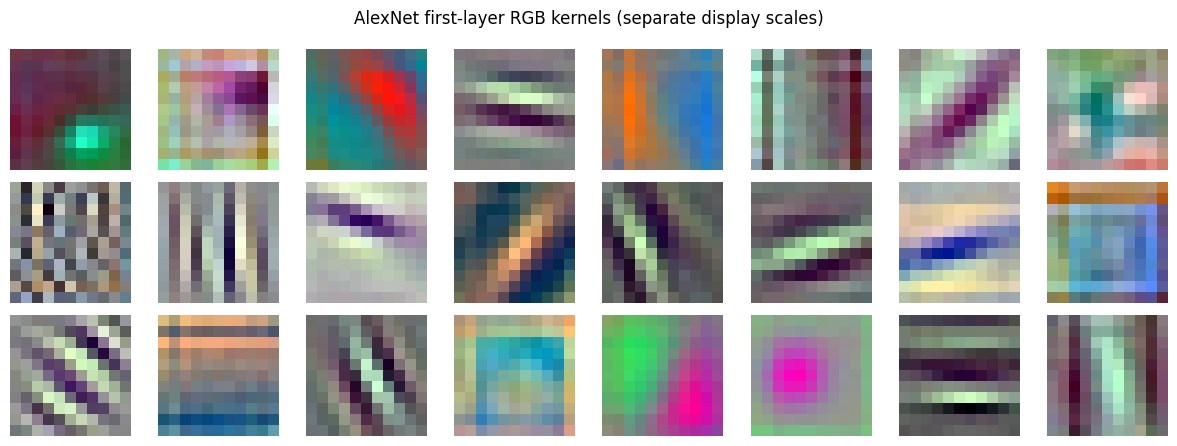

input: (1, 3, 224, 224) first ReLU: (1, 64, 55, 55)


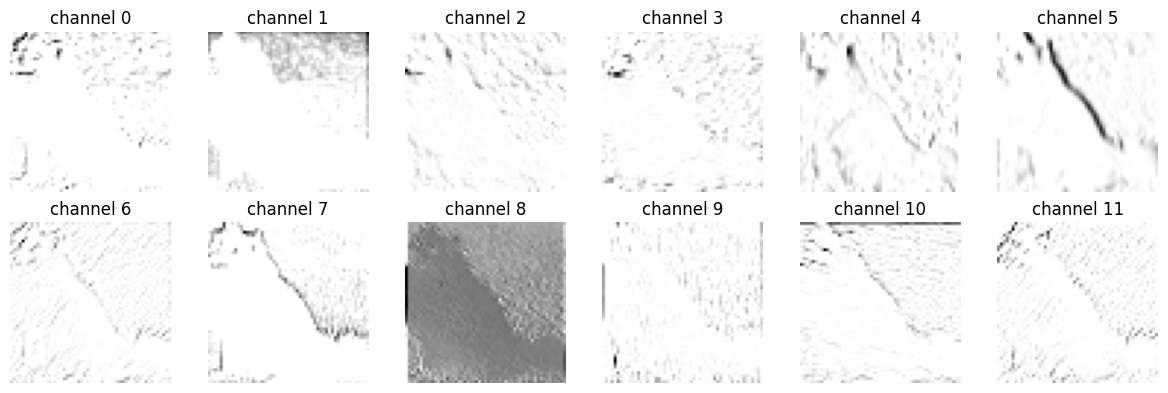

In [4]:
alex = networks['AlexNet']
filters = alex.features[0].weight.detach().cpu().permute(0,2,3,1).numpy()
fig, axes = plt.subplots(3, 8, figsize=(12, 4.5))
for j, ax in enumerate(axes.flat):
    kernel = filters[j]
    ax.imshow((kernel-kernel.min()) / max(float(np.ptp(kernel)), 1e-8))
    ax.axis('off')
plt.suptitle('AlexNet first-layer RGB kernels (separate display scales)')
plt.tight_layout(); plt.show()
with torch.inference_mode():
    maps = alex.features[:2](inputs['AlexNet']).cpu()
print('input:', tuple(inputs['AlexNet'].shape), 'first ReLU:', tuple(maps.shape))
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for j, ax in enumerate(axes.flat):
    ax.imshow(maps[0,j], cmap='gray_r'); ax.set_title(f'channel {j}'); ax.axis('off')
plt.tight_layout(); plt.show()

## 4. ResNet and the shape of a shortcut

D2L motivates a residual block by asking how an added block can preserve a
useful representation. With an identity shortcut, the sum is $x+F(x)$;
learning a small correction $F(x)$ keeps the block close to the identity.
The ResNet-18 blocks here apply ReLU after that sum.

The D2L diagram uses $g(x)$ for the residual branch; we call it $F(x)$.
The dotted box is the branch whose weights are learned.

Figure: Zhang, Lipton, Li, and Smola, [*Dive into Deep Learning*, §8.6, Fig. 8.6.2](https://d2l.ai/chapter_convolutional-modern/resnet.html), CC BY-SA 4.0.
Downloaded from D2L; PNG conversion preserves the diagram.

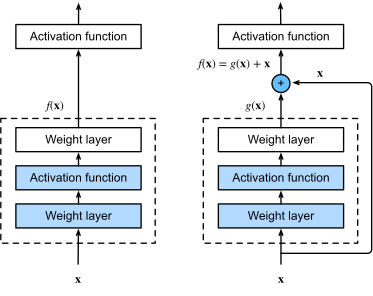

In [5]:
show_d2l_figure('residual-block', width=700)

### A $1\times1$ convolution mixes channels

At a single pixel, the input is a vector of $C_{\mathrm{in}}$ channel values.
A $1\times1$ convolution applies the same learned affine map to that vector
at every spatial position:
$$y_{n,o,h,w}=b_o+\sum_{c=1}^{C_{\mathrm{in}}}W_{o,c}x_{n,c,h,w},
\qquad W\in\mathbb R^{C_{\mathrm{out}}\times C_{\mathrm{in}}}.$$
The kernel has spatial size $1\times1$, but spans **all input channels**.
Each of its $C_{\mathrm{out}}$ filters produces one output channel. There is no
mixing between neighboring pixels at stride 1. It is a dense layer on channels,
repeated across the spatial grid with shared weights.

| Setting | Input | Output |
|---|---|---|
| 64 input channels, 128 filters, stride 1 | $N\times64\times56\times56$ | $N\times128\times56\times56$ |
| Same channels, stride 2 | $N\times64\times56\times56$ | $N\times128\times28\times28$ |

The number of filters changes the channel count. **Stride** changes the spatial
size. Both preserve the minibatch size $N$. With no bias, this map has
$128\cdot64=8192$ parameters.

D2L's illustration below shows three input channels and two output channels.
Figure: [*Dive into Deep Learning*, §7.4, Fig. 7.4.2](https://d2l.ai/chapter_convolutional-neural-networks/channels.html), CC BY-SA 4.0.
Downloaded from D2L and converted to PNG.

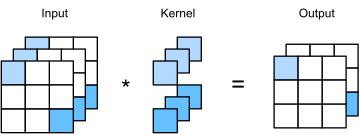

In [6]:
show_d2l_figure('conv-1x1')

In [7]:
# Check the channel-wise matrix multiplication without pretrained weights.
generator = torch.Generator().manual_seed(26513)
small_x = torch.randn(2, 3, 4, 4, generator=generator)
pointwise = nn.Conv2d(3, 2, kernel_size=1, bias=False)
with torch.no_grad():
    pointwise.weight.copy_(torch.tensor([[1., 2., -1.], [0.5, -1., 3.]]).reshape(2,3,1,1))
    conv_result = pointwise(small_x)
    matrix_result = torch.einsum('oc,nchw->nohw', pointwise.weight[:, :, 0, 0], small_x)
torch.testing.assert_close(conv_result, matrix_result)
print('Input:', tuple(small_x.shape), 'output:', tuple(conv_result.shape))
print('Each output pixel agrees with the same 2 by 3 matrix applied to its channels.')

Input: (2, 3, 4, 4) output: (2, 2, 4, 4)
Each output pixel agrees with the same 2 by 3 matrix applied to its channels.


### Match the branches before adding

Write a block as
$$y=\operatorname{ReLU}\bigl(F(x)+S(x)\bigr).$$
Use $S(x)=x$ when both branches have the same shape. When a stage changes
channels or resolution, use a learned **projection shortcut**. The D2L figure
shows the identity shortcut on the left and the $1\times1$ projection on the right.
In TorchVision's ResNet-18, the projection also includes batch normalization.

For the first block of `layer2`, the paths are:

| Path | Operation | Tensor shape |
|---|---|---|
| Input | — | $N\times64\times56\times56$ |
| Main | $3\times3$ convolution, stride 2, padding 1; BN; ReLU | $N\times128\times28\times28$ |
| Main | $3\times3$ convolution, stride 1, padding 1; BN | $N\times128\times28\times28$ |
| Shortcut | $1\times1$ convolution, stride 2, padding 0; BN | $N\times128\times28\times28$ |
| Addition and ReLU | $\operatorname{ReLU}(F(x)+S(x))$ | $N\times128\times28\times28$ |

The main branch is added to **the transformed input** $S(x)$ at this transition.
There is no addition of tensors with different shapes.

Figure: [*Dive into Deep Learning*, §8.6, Fig. 8.6.3](https://d2l.ai/chapter_convolutional-modern/resnet.html), CC BY-SA 4.0.
Downloaded from D2L and converted to PNG; the figure's shortcut omits the
additional BN used by TorchVision.

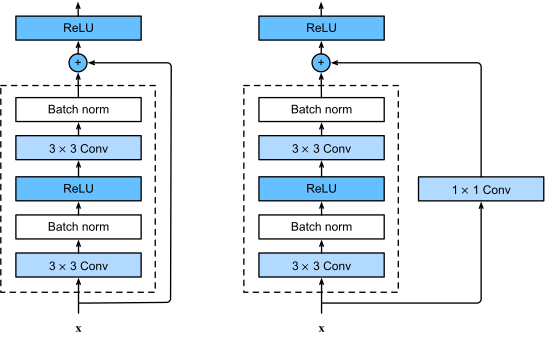

In [8]:
show_d2l_figure('resnet-block', width=800)

### Verify both types of block

We reconstruct an identity block in `layer1[0]` and the projection block in
`layer2[0]` from their actual pretrained layers. The main branch is
$$F(x)=\operatorname{BN}_2\left(K_2*
\operatorname{ReLU}\bigl(\operatorname{BN}_1(K_1*x)\bigr)\right).$$
For the identity block, a zero residual preserves the nonnegative input.
For the projection block, the shortcut itself learns a new channel representation.
The assertions check that the branch shapes agree and that the reconstructed
computation matches the library forward method.

In [9]:
resnet = networks['ResNet-18']
def check_block(block, x):
    with torch.inference_mode():
        branch = block.bn1(block.conv1(x)).relu()
        branch = block.bn2(block.conv2(branch))
        shortcut = x if block.downsample is None else block.downsample(x)
        assert branch.shape == shortcut.shape
        reconstructed = (branch + shortcut).relu()
        actual = block(x)
    torch.testing.assert_close(actual, reconstructed)
    print('input', tuple(x.shape), 'branch', tuple(branch.shape),
          'shortcut', tuple(shortcut.shape), 'max error', (actual-reconstructed).abs().max().item())
    return actual
with torch.inference_mode():
    x = inputs['ResNet-18']
    stem = resnet.maxpool(resnet.relu(resnet.bn1(resnet.conv1(x))))
check_block(resnet.layer1[0], stem)
with torch.inference_mode():
    stage1 = resnet.layer1(stem)
print('Projection shortcut:', resnet.layer2[0].downsample)
check_block(resnet.layer2[0], stage1);

input (1, 64, 56, 56) branch (1, 64, 56, 56) shortcut (1, 64, 56, 56) max error 0.0
Projection shortcut: Sequential(
  (0): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
  (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)
input (1, 64, 56, 56) branch (1, 128, 28, 28) shortcut (1, 128, 28, 28) max error 0.0


## 5. A ResNet checkpoint from Hugging Face

The public `timm/resnet18.a1_in1k` checkpoint was trained with a different
recipe from TorchVision's ResNet-18. We load its weights and resolve its own
preprocessing configuration, then run the same photograph through it.
Differences in the predictions reflect the checkpoint and preprocessing as well
as the image.

The next cell installs `timm` if needed and loads the checkpoint directly from
the Hub. The model card's example supplies the loading and preprocessing pattern.

### Follow the tensor through the Hub model

This checkpoint's evaluation transform uses $288\times288$, rather than the
TorchVision checkpoint's $224\times224$. $N$ is the minibatch size; $C$ counts channels.
The code resolves preprocessing from the checkpoint and prints its configuration.

| Operation | Output tensor for this checkpoint |
|---|---|
| Model-specific preprocessing | $N\times 3\times 288\times 288$ |
| $7\times 7$ convolution, stride 2; BN; ReLU | $N\times 64\times 144\times 144$ |
| Max pooling | $N\times 64\times 72\times 72$ |
| layer1 | $N\times 64\times 72\times 72$ |
| layer2 | $N\times 128\times 36\times 36$ |
| layer3 | $N\times 256\times 18\times 18$ |
| layer4 | $N\times 512\times 9\times 9$ |
| Global average pooling and flatten | $N\times 512$ |
| Classifier | $N\times 1000$ |

The trace below prints the dimensions produced by the checkpoint's resolved
preprocessing and each stage of its forward pass.

In [10]:
import importlib.util
import subprocess
import sys
if importlib.util.find_spec('timm') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'timm>=1.0,<2'])
import timm
hf_model = timm.create_model('hf-hub:timm/resnet18.a1_in1k', pretrained=True).to(device).eval()
config = timm.data.resolve_model_data_config(hf_model)
hf_transform = timm.data.create_transform(**config, is_training=False)
hf_input = hf_transform(image).unsqueeze(0).to(device)
with torch.inference_mode():
    hf_prob = hf_model(hf_input).softmax(1)[0].cpu()
values, indices = hf_prob.topk(5)
labels = models.ResNet18_Weights.DEFAULT.meta['categories']  # same ImageNet-1k label ordering
print('Hub checkpoint; preprocessing:', config)
display(pd.DataFrame({'label': [labels[i] for i in indices.tolist()],
                      'probability': values.tolist()}))

Hub checkpoint; preprocessing: {'input_size': [3, 224, 224], 'interpolation': 'bicubic', 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225], 'crop_pct': 0.95, 'crop_mode': 'center'}


,label,probability
0,Samoyed,0.999622
1,white wolf,0.000086
2,Pomeranian,0.000055
3,Eskimo dog,0.000023
4,keeshond,0.000022


In [11]:
with torch.inference_mode():
    z = hf_input
    print('Hub input', tuple(z.shape))
    for name in ['conv1', 'bn1', 'act1', 'maxpool', 'layer1', 'layer2', 'layer3', 'layer4', 'global_pool', 'fc']:
        z = getattr(hf_model, name)(z)
        print(name, tuple(z.shape))
    assert z.shape == (1, 1000)


Hub input (1, 3, 224, 224)
conv1 (1, 64, 112, 112)
bn1 (1, 64, 112, 112)
act1 (1, 64, 112, 112)
maxpool (1, 64, 56, 56)
layer1 (1, 64, 56, 56)
layer2 (1, 128, 28, 28)
layer3 (1, 256, 14, 14)
layer4 (1, 512, 7, 7)
global_pool (1, 512)
fc (1, 1000)


## 6. Experiments to try

1. **New images.** Upload a photograph and change `IMAGE_PATH`. Compare the
   top-five labels. Which visible features might explain the predictions?
2. **Transformations.** Rotate the photograph or crop out its background.
   How do the predictions change? Relate this to the lecture's distinction
   between translation equivariance of a convolution and invariance of a classifier.
3. **Shortcuts.** Write down the two branch shapes in `layer2[0]`. What would
   fail if its projection shortcut were replaced by an identity?
4. **Transfer learning.** Replace the final 1,000-class layer with a two-class
   layer. How many trainable parameters would it have? Which layers would you
   freeze with a small labeled dataset, and which would you update?

The companion `lenet-mnist.ipynb` trains a CNN from scratch. Together the two
notebooks connect the mechanics of learning filters with the features and
residual architecture of larger trained networks.

### Sources

- Ben Trevett, [*PyTorch Image Classification*](https://github.com/bentrevett/pytorch-image-classification),
  especially `3_alexnet.ipynb` and `5_resnet.ipynb`: architecture progression,
  pretrained models, and filter inspection. Copyright © 2018 Ben Trevett,
  MIT license; see `LICENSE-bentrevett`.
- [TorchVision AlexNet documentation](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.alexnet.html)
  and [ResNet-18 documentation](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html):
  model implementations, weights, transforms, and ImageNet category names.
  The photograph is from the [PyTorch Hub image examples](https://github.com/pytorch/hub/tree/master/images).
- Hugging Face / timm, [ResNet-18 model card](https://huggingface.co/timm/resnet18.a1_in1k):
  Hub loading and model-specific preprocessing example, adapted in Section 5.
  The model card declares the checkpoint's Apache-2.0 license.
- SDS265 Lectures 12–13: evaluation mode, parameter sharing, channel dimensions,
  learned features, batch normalization, and residual connections.

The code and explanations here are written for SDS265. The accompanying
[README](README.md) records the upstream revision and the changes for this lesson.
- Zhang, Lipton, Li, and Smola, *Dive into Deep Learning*, §§7.4 and 8.6: channel mixing and residual diagrams, CC BY-SA 4.0; see `figures/README.md`.
